<a href="https://colab.research.google.com/github/isaagianni/TP_Final_Vision/blob/main/notebooks/01_exploracion_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploración del Dataset AI Cook

Trabajo Práctico Final – Visión Artificial

Análisis exploratorio del dataset utilizado para la detección de alimentos en heladeras y la posterior comparación de modelos YOLO y DETR.

In [2]:
from google.colab import files
uploaded = files.upload()

Saving aicook.v1i.yolov8.zip to aicook.v1i.yolov8.zip


In [3]:
from pathlib import Path
from zipfile import ZipFile

zip_name = next(iter(uploaded))
dataset_dir = Path("/content/ai_cook")

with ZipFile(zip_name, "r") as zip_file:
    zip_file.extractall(dataset_dir)

print("Dataset descomprimido correctamente")
print("\nArchivos y carpetas:")
for item in sorted(dataset_dir.iterdir()):
    print(item.name)


Dataset descomprimido correctamente

Archivos y carpetas:
README.dataset.txt
README.roboflow.txt
data.yaml
test
train
valid


In [4]:

import yaml

# Leer la configuración del dataset
with open(dataset_dir / "data.yaml", "r") as file:
    data = yaml.safe_load(file)

# Mostrar las clases
print("Cantidad de clases:", data["nc"])
print("\nClases de alimentos:")
for name in data["names"]:
    print(name)

# Contar imágenes y anotaciones
print("\nDistribución del dataset:")

for split in ["train", "valid", "test"]:
    image_dir = dataset_dir / split / "images"
    label_dir = dataset_dir / split / "labels"

    images = list(image_dir.glob("*.jpg"))
    labels = list(label_dir.glob("*.txt"))

    print(f"{split}: {len(images)} imágenes, {len(labels)} anotaciones")


Cantidad de clases: 30

Clases de alimentos:
apple
banana
beef
blueberries
bread
butter
carrot
cheese
chicken
chicken_breast
chocolate
corn
eggs
flour
goat_cheese
green_beans
ground_beef
ham
heavy_cream
lime
milk
mushrooms
onion
potato
shrimp
spinach
strawberries
sugar
sweet_potato
tomato

Distribución del dataset:
train: 362 imágenes, 362 anotaciones
valid: 103 imágenes, 103 anotaciones
test: 51 imágenes, 51 anotaciones


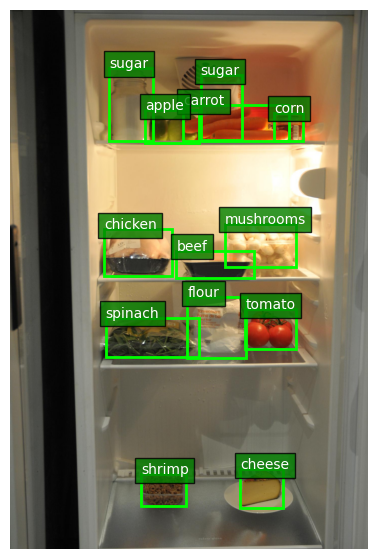

In [5]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# Elegir una imagen de entrenamiento
image_dir = dataset_dir / "train" / "images"
image_path = sorted(image_dir.glob("*.jpg"))[0]

# Abrir la imagen
image = Image.open(image_path)
width, height = image.size

# Buscar su archivo de anotaciones
label_path = dataset_dir / "train" / "labels" / (image_path.stem + ".txt")

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(image)

# Dibujar los bounding boxes
with open(label_path, "r") as file:
    for line in file:
        values = line.split()

        class_id = int(values[0])
        xc, yc, w, h = map(float, values[1:])

        # Convertir coordenadas normalizadas a píxeles
        x = (xc - w / 2) * width
        y = (yc - h / 2) * height
        box_width = w * width
        box_height = h * height

        # Dibujar rectángulo
        rect = patches.Rectangle(
            (x, y), box_width, box_height,
            linewidth=2,
            edgecolor="lime",
            facecolor="none"
        )
        ax.add_patch(rect)

        # Mostrar nombre del alimento
        ax.text(
            x, y, data["names"][class_id],
            color="white",
            bbox={"facecolor": "green", "alpha": 0.8}
        )

ax.axis("off")
plt.show()


# Analizar la distribución de clases
Necesitamos saber cuántos ejemplos tenemos de cada alimento.

In [6]:
from collections import Counter
import pandas as pd

class_names = data["names"]

# Contar objetos de cada clase en cada conjunto
counts = {}

for split in ["train", "valid", "test"]:
    counter = Counter()
    label_dir = dataset_dir / split / "labels"

    for label_path in label_dir.glob("*.txt"):
        with open(label_path, "r") as file:
            for line in file:
                if line.strip():
                    class_id = int(line.split()[0])
                    counter[class_id] += 1

    counts[split] = counter

# Crear tabla de distribución de clases
rows = []

for class_id, name in enumerate(class_names):
    train_count = counts["train"][class_id]
    valid_count = counts["valid"][class_id]
    test_count = counts["test"][class_id]

    rows.append({
        "Clase": name,
        "Train": train_count,
        "Valid": valid_count,
        "Test": test_count,
        "Total": train_count + valid_count + test_count
    })

df_classes = pd.DataFrame(rows)
df_classes = df_classes.sort_values(
    "Total", ascending=False
)

display(df_classes)

print("Total de objetos anotados:", df_classes["Total"].sum())


,Clase,Train,Valid,Test,Total
27,sugar,229,78,12,319
29,tomato,236,59,12,307
26,strawberries,230,51,24,305
13,flour,197,58,46,301
23,potato,213,64,23,300
7,cheese,221,49,30,300
20,milk,168,48,44,260
15,green_beans,169,47,25,241
24,shrimp,182,42,15,239
11,corn,171,48,18,237


Total de objetos anotados: 6396


Observación: La clase sugar tiene casi cuatro veces más ejemplos que ham. Entonces hay un desbalance de clases, y puede influir en el entrenamiento, porque algunas clases tienen muchos más ejemplos que otras.  
Hay dos clases que no aparecen en el test
- goat_cheese: 106 objetos en total, pero 0 en test.
- ham: 81 objetos en total, pero 0 en test.  
Entonces cuando evaluemos los modelos sobre el test de AI Cook, no podremos medir adecuadamente su capacidad para detectar esas dos clases, porque no hay ejemplos reales de ellas en ese conjunto.
Por eso, antes de entrenar, hay que revisar la calidad de la división original y los posibles duplicados.

# Gráfico de distribución de clases

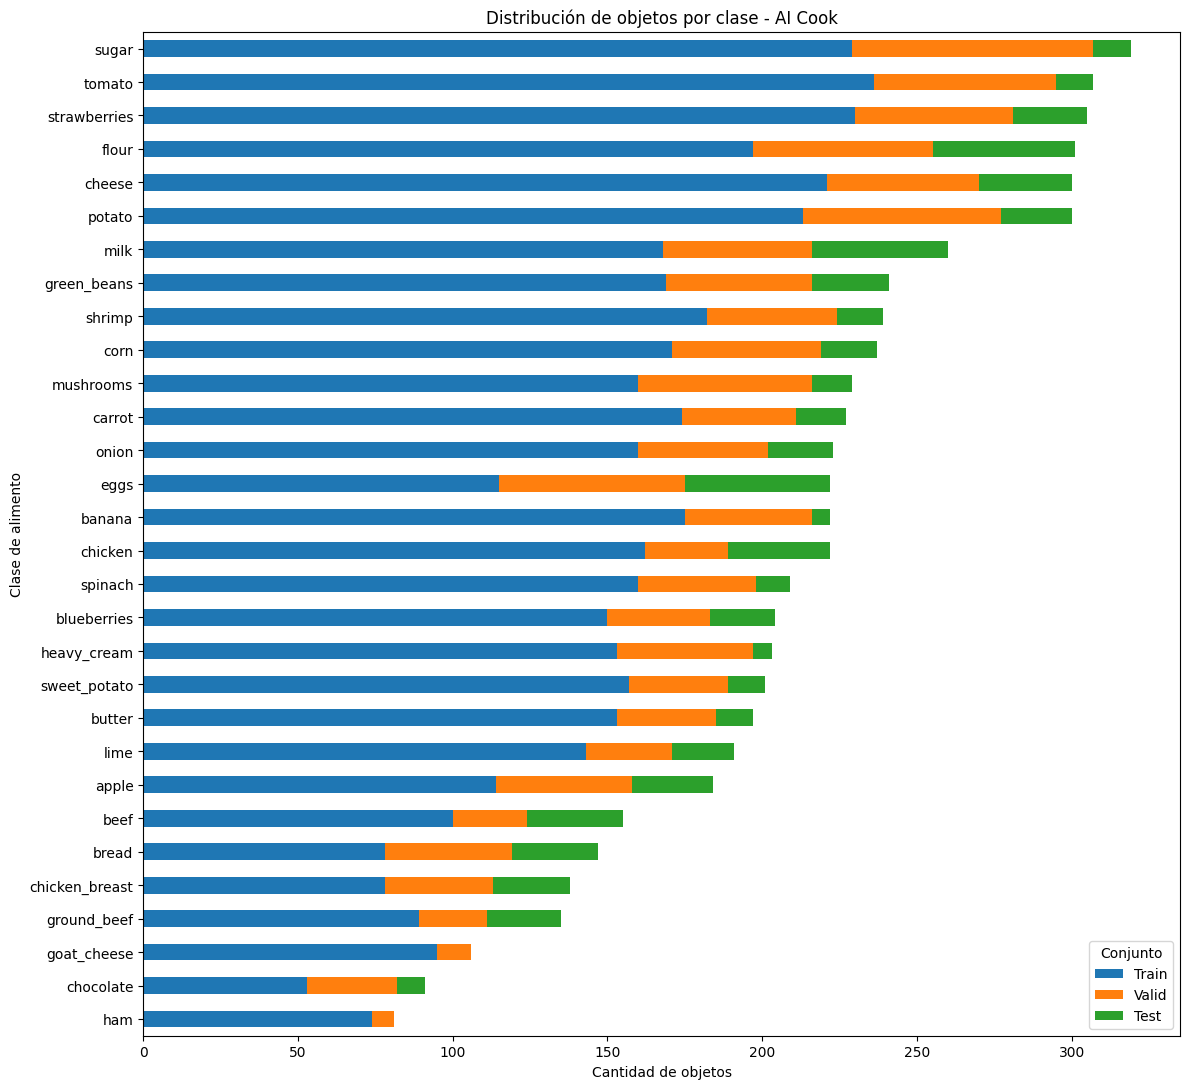

In [6]:
import matplotlib.pyplot as plt

# Ordenar las clases por cantidad total de objetos
df_plot = df_classes.sort_values("Total", ascending=True)

# Graficar la cantidad de objetos en cada conjunto
ax = df_plot.set_index("Clase")[["Train", "Valid", "Test"]].plot(
    kind="barh",
    stacked=True,
    figsize=(12, 11)
)

plt.title("Distribución de objetos por clase - AI Cook")
plt.xlabel("Cantidad de objetos")
plt.ylabel("Clase de alimento")
plt.legend(title="Conjunto")
plt.tight_layout()
plt.show()


El dataset está desbalanceado: algunas clases, como sugar, tomato y strawberries, tienen más ejemplos que otras, como ham y chocolate.

Hay clases sin ejemplos en test: ham y goat_cheese no aparecen en el conjunto de prueba, por lo que no podremos evaluar su detección mediante ejemplos positivos en ese conjunto.

La distribución cambia según la clase: no todas tienen la misma proporción de objetos en train, validación y test.

# Analizar el tamaño de los objetos

Cantidad de objetos: 4559
Área mediana: 1.22%
Área mínima: 0.11%
Área máxima: 5.63%


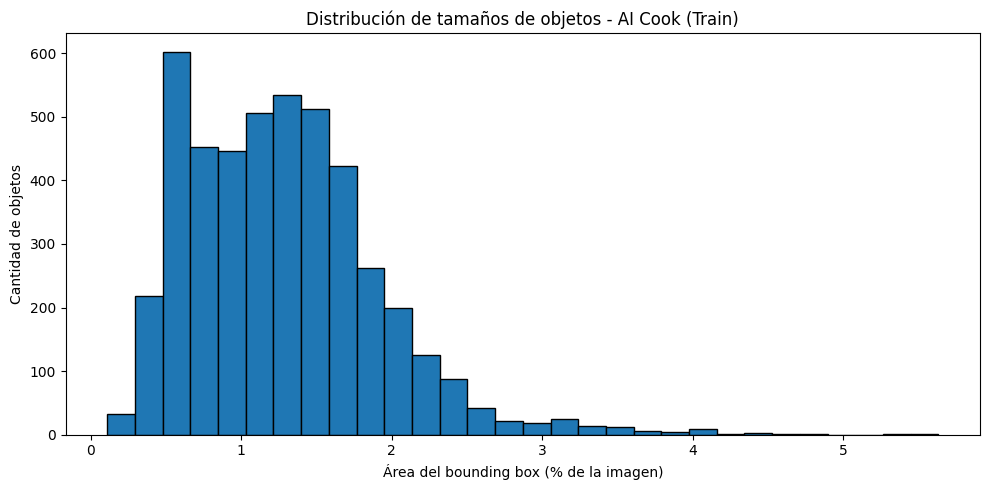

In [7]:

import numpy as np
import matplotlib.pyplot as plt

areas = []

label_dir = dataset_dir / "train" / "labels"

for label_path in label_dir.glob("*.txt"):
    with open(label_path, "r") as file:
        for line in file:
            values = line.split()

            if not values:
                continue

            # Ancho y alto normalizados del bounding box
            width = float(values[3])
            height = float(values[4])

            # Porcentaje de la imagen ocupado por el objeto
            area = width * height * 100
            areas.append(area)

print("Cantidad de objetos:", len(areas))
print(f"Área mediana: {np.median(areas):.2f}%")
print(f"Área mínima: {np.min(areas):.2f}%")
print(f"Área máxima: {np.max(areas):.2f}%")

plt.figure(figsize=(10, 5))
plt.hist(areas, bins=30, edgecolor="black")

plt.title("Distribución de tamaños de objetos - AI Cook (Train)")
plt.xlabel("Área del bounding box (% de la imagen)")
plt.ylabel("Cantidad de objetos")
plt.tight_layout()
plt.show()


# Buscar imágenes exactamente duplicadas

In [8]:

import hashlib
from collections import defaultdict

hashes = defaultdict(list)

for split in ["train", "valid", "test"]:
    image_dir = dataset_dir / split / "images"

    for image_path in image_dir.iterdir():
        if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        # Calcular una huella digital de la imagen
        image_hash = hashlib.sha256(image_path.read_bytes()).hexdigest()

        hashes[image_hash].append((split, image_path.name))

# Buscar imágenes idénticas en conjuntos diferentes
duplicates = []

for files in hashes.values():
    splits = set(split for split, name in files)

    if len(splits) > 1:
        duplicates.append(files)

print("Grupos de imágenes duplicadas entre conjuntos:", len(duplicates))

for group in duplicates[:10]:
    print(group)


Grupos de imágenes duplicadas entre conjuntos: 0


# Buscar imágenes muy parecidas
el modelo podría obtener resultados muy buenos en el test simplemente porque ya vio escenas prácticamente iguales durante el entrenamiento.  
Buscamos imágenes visualmente similares utilizando un método llamado perceptual hashing (pHash).

Pares potencialmente similares: 7057


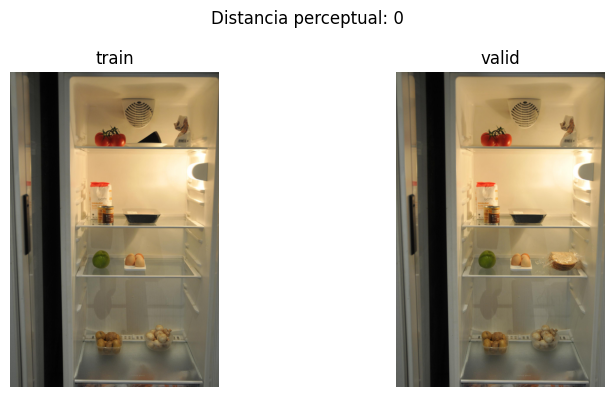

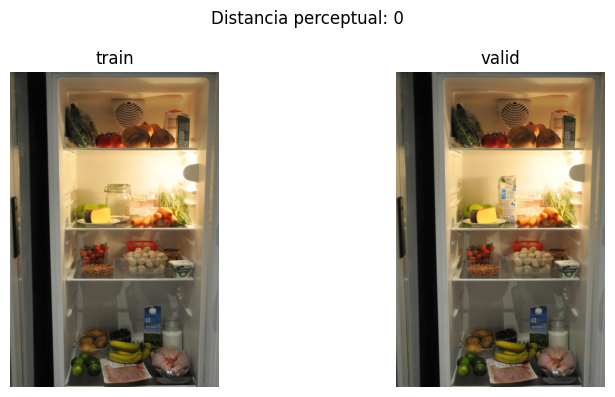

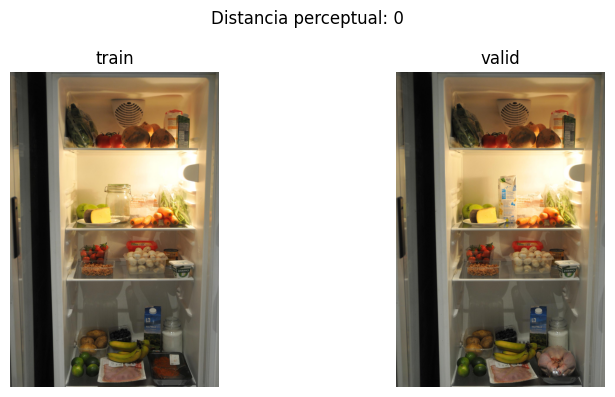

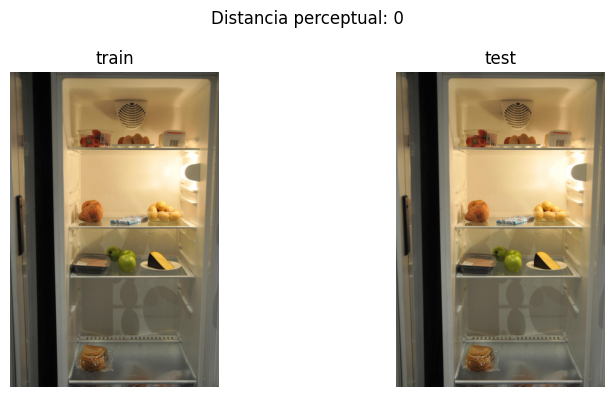

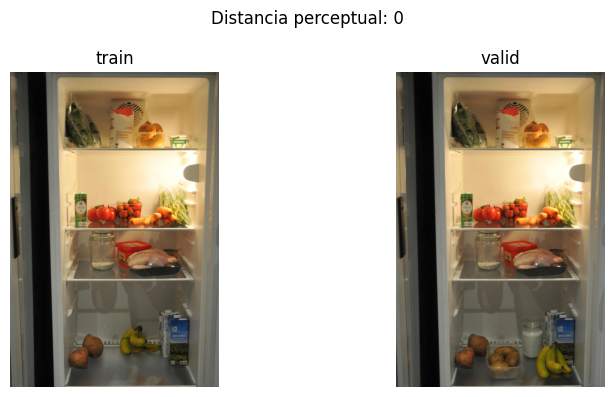

In [9]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def perceptual_hash(image_path):
    image = Image.open(image_path).convert("L")
    image = image.resize((32, 32))

    dct = cv2.dct(np.float32(image))
    values = dct[:8, :8].flatten()

    median = np.median(values[1:])
    return values > median

# Obtener imágenes y calcular sus hashes
images = []

for split in ["train", "valid", "test"]:
    folder = dataset_dir / split / "images"

    for path in folder.iterdir():
        if path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            images.append((split, path, perceptual_hash(path)))

# Comparar imágenes de conjuntos diferentes
similar_pairs = []

for i in range(len(images)):
    for j in range(i + 1, len(images)):
        split1, path1, hash1 = images[i]
        split2, path2, hash2 = images[j]

        if split1 == split2:
            continue

        distance = np.count_nonzero(hash1 != hash2)

        if distance <= 8:
            similar_pairs.append((distance, path1, path2))

similar_pairs.sort(key=lambda x: x[0])

print("Pares potencialmente similares:", len(similar_pairs))

# Mostrar los 5 pares más similares
for distance, path1, path2 in similar_pairs[:5]:
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))

    axes[0].imshow(Image.open(path1))
    axes[0].set_title(path1.parent.parent.name)

    axes[1].imshow(Image.open(path2))
    axes[1].set_title(path2.parent.parent.name)

    for ax in axes:
        ax.axis("off")

    plt.suptitle(f"Distancia perceptual: {distance}")
    plt.tight_layout()
    plt.show()


In [10]:

from skimage.metrics import structural_similarity as ssim
from PIL import Image
import numpy as np

def calculate_ssim(path1, path2):
    img1 = Image.open(path1).convert("RGB").resize((256, 256))
    img2 = Image.open(path2).convert("RGB").resize((256, 256))

    img1 = np.array(img1)
    img2 = np.array(img2)

    return ssim(
        img1,
        img2,
        channel_axis=2,
        data_range=255
    )

# Comparar los primeros 5 pares encontrados
for i, (distance, path1, path2) in enumerate(similar_pairs[:5]):
    score = calculate_ssim(path1, path2)

    print(f"Par {i + 1}:")
    print(f"  pHash: {distance}")
    print(f"  SSIM: {score:.4f}")
    print()


Par 1:
  pHash: 0
  SSIM: 0.9488

Par 2:
  pHash: 0
  SSIM: 0.9614

Par 3:
  pHash: 0
  SSIM: 0.9120

Par 4:
  pHash: 0
  SSIM: 0.9861

Par 5:
  pHash: 0
  SSIM: 0.9278



# Validar las anotaciones de AI Cook.

In [11]:

from pathlib import Path

errors = []
statistics = {}

for split in ["train", "valid", "test"]:

    label_dir = dataset_dir / split / "labels"
    image_dir = dataset_dir / split / "images"

    valid_boxes = 0
    invalid_boxes = 0
    empty_files = 0

    image_files = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    for image_path in image_files:

        label_path = label_dir / f"{image_path.stem}.txt"

        if not label_path.exists():
            errors.append((split, image_path.name, "Etiqueta faltante"))
            continue

        lines = label_path.read_text().splitlines()

        if not lines:
            empty_files += 1

        for line_number, line in enumerate(lines, start=1):

            values = line.split()

            if len(values) != 5:
                invalid_boxes += 1
                errors.append(
                    (split, label_path.name, line_number, "Formato incorrecto")
                )
                continue

            try:
                class_value = float(values[0])
                class_id = int(class_value)
                x, y, w, h = map(float, values[1:])

                valid = (
                    class_value == class_id
                    and 0 <= class_id < 30
                    and 0 < w <= 1
                    and 0 < h <= 1
                    and w / 2 <= x <= 1 - w / 2
                    and h / 2 <= y <= 1 - h / 2
                )

                if valid:
                    valid_boxes += 1
                else:
                    invalid_boxes += 1
                    errors.append(
                        (split, label_path.name, line_number, "Valores inválidos")
                    )

            except ValueError:
                invalid_boxes += 1
                errors.append(
                    (split, label_path.name, line_number, "Valor no numérico")
                )

    statistics[split] = {
        "valid_boxes": valid_boxes,
        "invalid_boxes": invalid_boxes,
        "empty_files": empty_files
    }

for split, stats in statistics.items():
    print(f"\n{split.upper()}")
    print("Bounding boxes válidos:", stats["valid_boxes"])
    print("Bounding boxes inválidos:", stats["invalid_boxes"])
    print("Archivos de etiquetas vacíos:", stats["empty_files"])

print("\nTOTAL DE ERRORES:", len(errors))
print("\nPrimeros errores:", errors[:10])



TRAIN
Bounding boxes válidos: 4559
Bounding boxes inválidos: 0
Archivos de etiquetas vacíos: 0

VALID
Bounding boxes válidos: 1227
Bounding boxes inválidos: 0
Archivos de etiquetas vacíos: 0

TEST
Bounding boxes válidos: 610
Bounding boxes inválidos: 0
Archivos de etiquetas vacíos: 0

TOTAL DE ERRORES: 0

Primeros errores: []


# contar cuántos pares similares hay entre conjuntos diferentes

In [15]:
%pip install ImageHash
import imagehash
from PIL import Image
import pandas as pd
from pathlib import Path

# En este notebook, dataset_dir debe apuntar a AI Cook
splits = ["train", "valid", "test"]
hashes = {}

for split in splits:
    image_dir = dataset_dir / split / "images"

    hashes[split] = {}

    for path in image_dir.iterdir():
        if path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        with Image.open(path) as image:
            hashes[split][path.name] = imagehash.phash(image)

# Comparar imágenes de conjuntos diferentes
results = []

split_pairs = [
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test")
]

for split1, split2 in split_pairs:
    for name1, hash1 in hashes[split1].items():
        for name2, hash2 in hashes[split2].items():

            distance = hash1 - hash2

            if distance <= 8:
                results.append({
                    "Conjunto 1": split1,
                    "Imagen 1": name1,
                    "Conjunto 2": split2,
                    "Imagen 2": name2,
                    "pHash": distance
                })

df_cross_split = pd.DataFrame(results)

print("Pares similares entre conjuntos:", len(df_cross_split))

if not df_cross_split.empty:
    print("\nCantidad por comparación:")
    print(
        df_cross_split.groupby(
            ["Conjunto 1", "Conjunto 2"]
        ).size()
    )

    print("\nPares más similares:")
    display(df_cross_split.sort_values("pHash").head(15))


Pares similares entre conjuntos: 7169

Cantidad por comparación:
Conjunto 1  Conjunto 2
train       test          1579
            valid         5067
valid       test           523
dtype: int64

Pares más similares:


,Conjunto 1,Imagen 1,Conjunto 2,Imagen 2,pHash
4605,train,DSC_5939_JPG_jpg.rf.69f52e275fc77367b25f7a952f...,valid,DSC_5940_JPG_jpg.rf.52dfcbb4816b4d7385e9f56f3e...,0
636,train,DSC_6188_JPG_jpg.rf.450f17cc3a2dd571d8b6066156...,valid,DSC_6187_JPG_jpg.rf.3b9c26230ab2594091395026e2...,0
4431,train,DSC_5957_JPG_jpg.rf.2091b43c8305f154a182378a75...,valid,DSC_5956_JPG_jpg.rf.b8824697f1d18b1de4872cce7d...,0
4498,train,DSC_5801_JPG_jpg.rf.6896db1f0b0a4d16ccf0177865...,valid,DSC_5748_JPG_jpg.rf.d30d06d3b6bd864dc1e6ac0325...,0
2779,train,DSC_5789_JPG_jpg.rf.fdff3cff1a95c85acc5572eb74...,valid,DSC_5790_JPG_jpg.rf.be5b9eee05eb65873743cdca6c...,0
3241,train,DSC_5798_JPG_jpg.rf.f64c54a73a2d9aac438e71151d...,valid,DSC_5748_JPG_jpg.rf.d30d06d3b6bd864dc1e6ac0325...,0
1359,train,DSC_5803_JPG_jpg.rf.c12c8974ac6096dfd0744dc8d6...,valid,DSC_5804_JPG_jpg.rf.eb50260728457f257c904d2068...,0
1737,train,DSC_5802_JPG_jpg.rf.2de5b82e2f4a5886623d81e529...,valid,DSC_5804_JPG_jpg.rf.eb50260728457f257c904d2068...,0
5807,train,DSC_5969_JPG_jpg.rf.46d61cfa0122df515f2fe08513...,test,DSC_5968_JPG_jpg.rf.a884e060199c18672c27bd9fce...,0
5903,train,DSC_5991_JPG_jpg.rf.0faf42d389201caebbacb53c84...,test,DSC_6080_JPG_jpg.rf.4d0d332f465c0e609ea3b3f1a7...,2


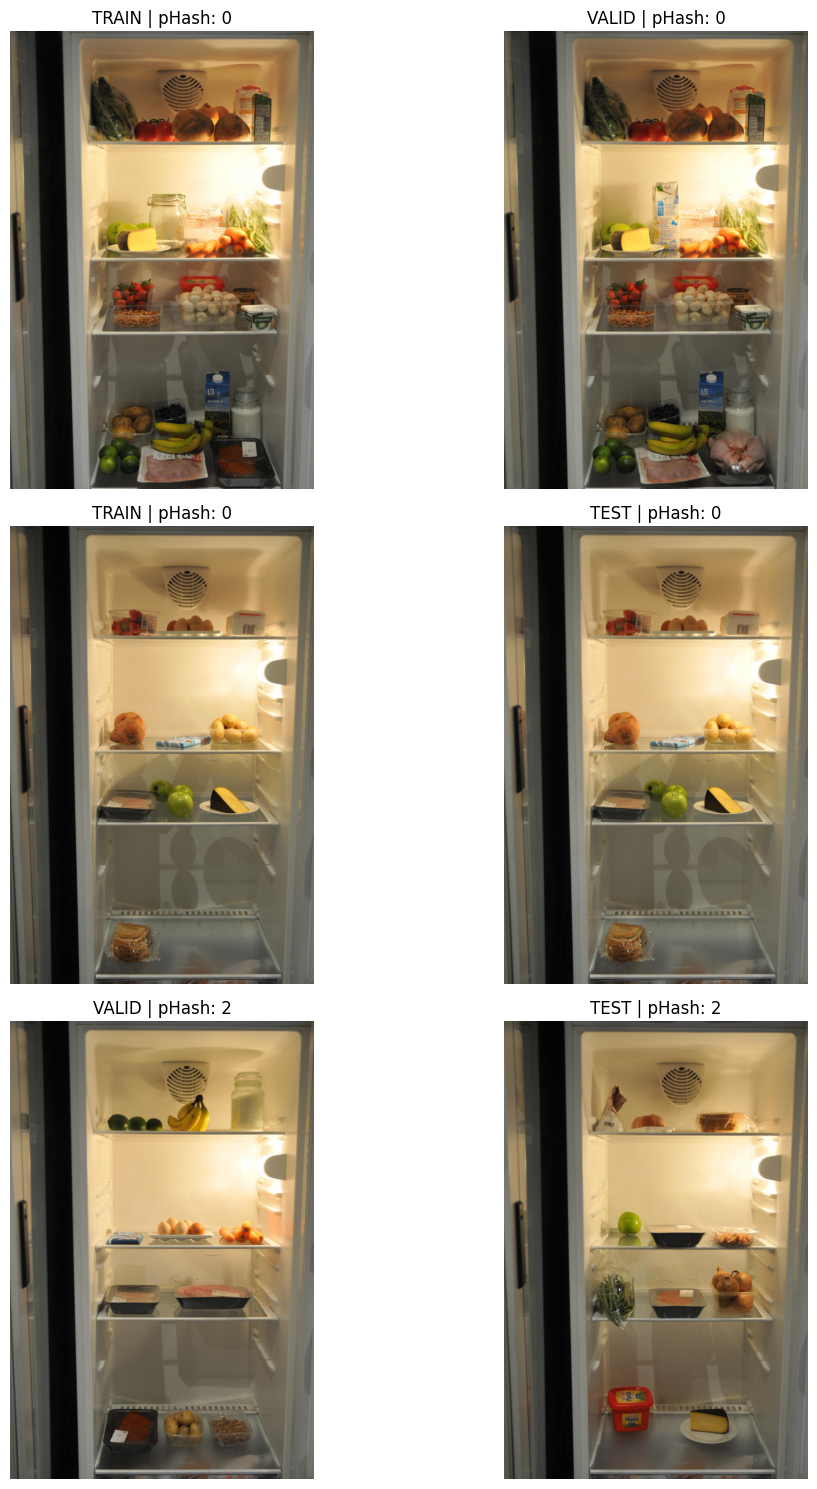

In [16]:

import matplotlib.pyplot as plt
from PIL import Image

# Elegir el par más similar de cada comparación
comparisons = [
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test")
]

selected_pairs = []

for split1, split2 in comparisons:

    subset = df_cross_split[
        (df_cross_split["Conjunto 1"] == split1) &
        (df_cross_split["Conjunto 2"] == split2)
    ].sort_values("pHash")

    if not subset.empty:
        selected_pairs.append(subset.iloc[0])

# Mostrar imágenes
fig, axes = plt.subplots(
    len(selected_pairs), 2,
    figsize=(12, 5 * len(selected_pairs)),
    squeeze=False
)

for i, pair in enumerate(selected_pairs):

    for j in range(2):

        split = pair[f"Conjunto {j + 1}"]
        name = pair[f"Imagen {j + 1}"]

        path = dataset_dir / split / "images" / name

        with Image.open(path) as image:
            axes[i, j].imshow(image.convert("RGB"))

        axes[i, j].set_title(
            f"{split.upper()} | pHash: {pair['pHash']}"
        )

        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


# Calcular SSIM entre las imágenes más sospechosas

In [17]:

import numpy as np
import pandas as pd
from PIL import Image
from skimage.metrics import structural_similarity as ssim
from functools import lru_cache

# Primero analizamos los pares con pHash <= 4
candidates = df_cross_split[
    df_cross_split["pHash"] <= 4
].copy()

print("Pares candidatos:", len(candidates))

# Cargar imágenes en escala de grises
@lru_cache(maxsize=None)
def load_image(split, name):
    path = dataset_dir / split / "images" / name

    with Image.open(path) as image:
        image = image.convert("L").resize((256, 256))
        return np.array(image)

# Calcular SSIM
ssim_values = []

for _, pair in candidates.iterrows():
    img1 = load_image(pair["Conjunto 1"], pair["Imagen 1"])
    img2 = load_image(pair["Conjunto 2"], pair["Imagen 2"])

    score = ssim(img1, img2, data_range=255)
    ssim_values.append(score)

candidates["SSIM"] = ssim_values

# Seleccionar los pares extremadamente similares
suspected_duplicates = candidates[
    candidates["SSIM"] >= 0.97
].sort_values("SSIM", ascending=False)

print("\nPares con SSIM >= 0.97:", len(suspected_duplicates))

print("\nCantidad por comparación:")
if not suspected_duplicates.empty:
    print(
        suspected_duplicates.groupby(
            ["Conjunto 1", "Conjunto 2"]
        ).size()
    )

print("\nLos 15 pares más similares:")
display(suspected_duplicates.head(15))


Pares candidatos: 404

Pares con SSIM >= 0.97: 4

Cantidad por comparación:
Conjunto 1  Conjunto 2
train       test          1
            valid         3
dtype: int64

Los 15 pares más similares:


,Conjunto 1,Imagen 1,Conjunto 2,Imagen 2,pHash,SSIM
4605,train,DSC_5939_JPG_jpg.rf.69f52e275fc77367b25f7a952f...,valid,DSC_5940_JPG_jpg.rf.52dfcbb4816b4d7385e9f56f3e...,0,0.996038
5807,train,DSC_5969_JPG_jpg.rf.46d61cfa0122df515f2fe08513...,test,DSC_5968_JPG_jpg.rf.a884e060199c18672c27bd9fce...,0,0.992337
4658,train,DSC_5741_JPG_jpg.rf.3282e86d4037c69ca753e3dd9f...,valid,DSC_5740_JPG_jpg.rf.5d8051ae1fb6a278e8233c2aad...,2,0.980528
3801,train,DSC_5744_JPG_jpg.rf.2f07bd08f1120d1aa82b42d2b5...,valid,DSC_5745_JPG_jpg.rf.2a390ebe128ebf3fb16aa4451f...,4,0.971443


Par 1: DSC_5939_JPG_jpg.rf.69f52e275fc77367b25f7a952f7dac71.jpg  /  DSC_5940_JPG_jpg.rf.52dfcbb4816b4d7385e9f56f3ec702bf.jpg
Par 2: DSC_5969_JPG_jpg.rf.46d61cfa0122df515f2fe08513a3c9ef.jpg  /  DSC_5968_JPG_jpg.rf.a884e060199c18672c27bd9fce57df56.jpg
Par 3: DSC_5741_JPG_jpg.rf.3282e86d4037c69ca753e3dd9f032806.jpg  /  DSC_5740_JPG_jpg.rf.5d8051ae1fb6a278e8233c2aad82dc57.jpg
Par 4: DSC_5744_JPG_jpg.rf.2f07bd08f1120d1aa82b42d2b5641f5e.jpg  /  DSC_5745_JPG_jpg.rf.2a390ebe128ebf3fb16aa4451fdeab5f.jpg


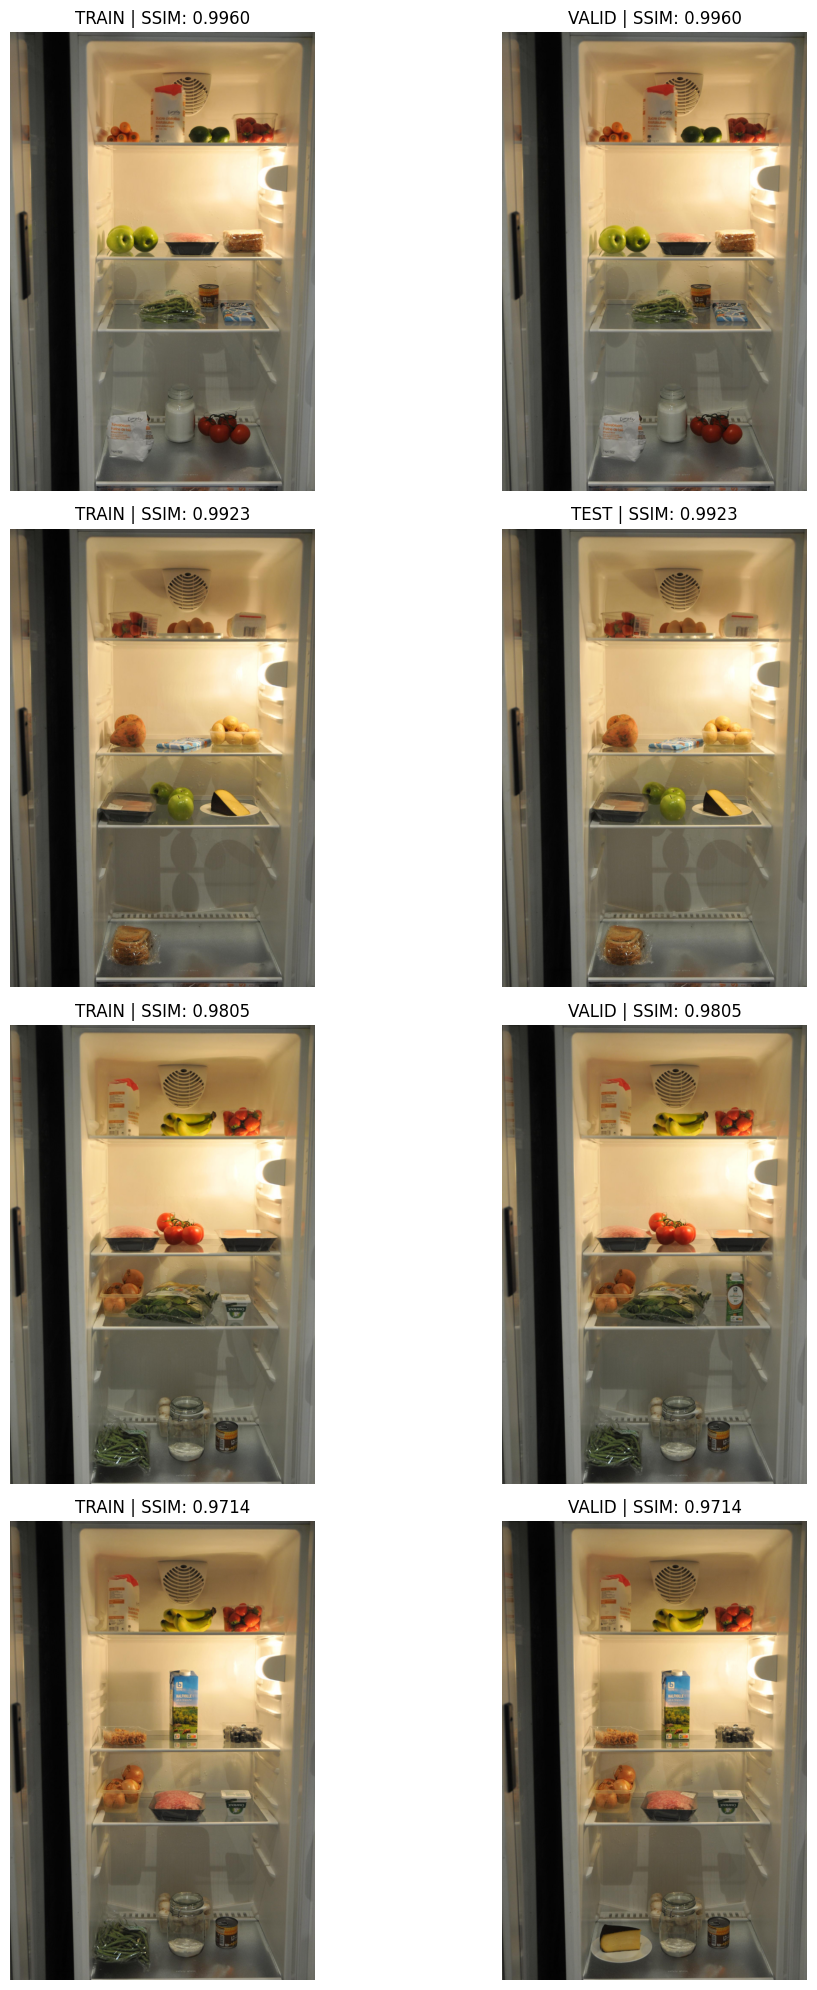

In [18]:

import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(4, 2, figsize=(12, 20))

for i, (_, pair) in enumerate(suspected_duplicates.iterrows()):

    for j in range(2):

        split = pair[f"Conjunto {j + 1}"]
        name = pair[f"Imagen {j + 1}"]

        image_path = dataset_dir / split / "images" / name

        with Image.open(image_path) as image:
            axes[i, j].imshow(image.convert("RGB"))

        axes[i, j].set_title(
            f"{split.upper()} | "
            f"SSIM: {pair['SSIM']:.4f}"
        )
        axes[i, j].axis("off")

    print(
        f"Par {i + 1}: "
        f"{pair['Imagen 1']}  /  {pair['Imagen 2']}"
    )

plt.tight_layout()
plt.show()


# Copia del dataset SIN imagenes casi iguales (solo sacamos las de train)  
Retiramos de TRAIN las dos fotografías prácticamente duplicadas que encontramos, sin modificar VALID ni TEST.

In [19]:

import shutil
from pathlib import Path

# Crear una copia del dataset original
clean_dir = Path("/content/ai_cook_clean")

if clean_dir.exists():
    raise FileExistsError("La carpeta limpia ya existe. Revisala antes de continuar.")

shutil.copytree(dataset_dir, clean_dir)

# Seleccionar los dos duplicados confirmados visualmente
duplicates = suspected_duplicates[
    (suspected_duplicates["Conjunto 1"] == "train") &
    (suspected_duplicates["SSIM"] >= 0.99)
]["Imagen 1"].unique()

print("Fotografías a retirar de TRAIN:", len(duplicates))

# Comprobar que existan imágenes y etiquetas
for name in duplicates:
    image_path = clean_dir / "train" / "images" / name
    label_path = clean_dir / "train" / "labels" / f"{Path(name).stem}.txt"

    assert image_path.exists(), f"No existe: {image_path}"
    assert label_path.exists(), f"No existe: {label_path}"

# Retirar los duplicados solamente de la copia
for name in duplicates:
    image_path = clean_dir / "train" / "images" / name
    label_path = clean_dir / "train" / "labels" / f"{Path(name).stem}.txt"

    image_path.unlink()
    label_path.unlink()

# Verificar cantidades finales
for split in ["train", "valid", "test"]:
    images = list((clean_dir / split / "images").glob("*"))
    print(f"{split.upper()}: {len(images)} imágenes")


Fotografías a retirar de TRAIN: 2
TRAIN: 360 imágenes
VALID: 103 imágenes
TEST: 51 imágenes


# Guardamos todo

In [20]:

from google.colab import drive
from pathlib import Path
import shutil

# Conectar Google Drive
drive.mount("/content/drive")

# Crear carpeta para guardar datasets
save_dir = Path("/content/drive/MyDrive/TP_Final_Vision/datasets")
save_dir.mkdir(parents=True, exist_ok=True)

# Comprimir el dataset limpio y guardarlo
zip_path = shutil.make_archive(
    str(save_dir / "ai_cook_clean"),
    "zip",
    root_dir=str(clean_dir)
)

print("Dataset guardado correctamente:")
print(zip_path)


Mounted at /content/drive
Dataset guardado correctamente:
/content/drive/MyDrive/TP_Final_Vision/datasets/ai_cook_clean.zip
